# 分位数回归与共形预测区间

用固定随机种子模拟输入不同、噪声幅度也不同的数据。把数据拆成拟合、校准与测试三部分。
对比机器学习模型直接拟合的分位数区间，以及 MAPIE 基于校准残差构造的分割共形区间。
以 90% 为目标覆盖率，同时比较实际覆盖率与区间宽度。

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mapie.regression import SplitConformalRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

def interval_metrics(actual, lower, upper):
    covered = (actual >= lower) & (actual <= upper)
    return {"coverage": covered.mean(), "mean_width": (upper - lower).mean()}

rng = np.random.default_rng(114)
x = rng.uniform(-3, 3, size=(900, 2))
y = 2 * np.sin(x[:, 0]) + 0.8 * x[:, 1] + rng.normal(scale=0.2 + 0.35 * np.abs(x[:, 0]))
train, calibration, test = np.split(rng.permutation(len(y)), [450, 675])

fitted = HistGradientBoostingRegressor(random_state=0).fit(x[train], y[train])
mapie = SplitConformalRegressor(estimator=fitted, confidence_level=0.90, prefit=True)
mapie.conformalize(x[calibration], y[calibration])
_, bounds = mapie.predict_interval(x[test])
mapie_lower, mapie_upper = bounds[:, 0, 0], bounds[:, 1, 0]

quantile_bounds = []
for level in (0.05, 0.95):
    model = HistGradientBoostingRegressor(loss="quantile", quantile=level, random_state=0)
    quantile_bounds.append(model.fit(x[train], y[train]).predict(x[test]))
q_lower, q_upper = np.sort(np.vstack(quantile_bounds), axis=0)

pd.DataFrame({
    "Quantile regression": interval_metrics(y[test], q_lower, q_upper),
    "MAPIE split conformal": interval_metrics(y[test], mapie_lower, mapie_upper),
}).T.round(3)

,coverage,mean_width
Quantile regression,0.751,2.023
MAPIE split conformal,0.889,2.663


## 时间序列按时间校准

下面预先固定点预测模型，每一步用最近已观测样本的残差更新区间。
在时序依赖及噪声改变的情况下，用逐期回测衡量覆盖率。

coverage      0.857
mean_width    2.766
dtype: float64


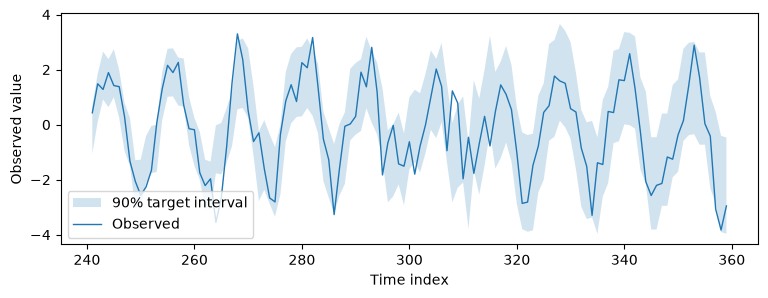

In [2]:
times = np.arange(360)
series = np.zeros(len(times))
for k in range(1, len(times)):
    scale = 0.45 if k < 260 else 0.95
    series[k] = 0.58 * series[k - 1] + np.sin(2 * np.pi * k / 12) + rng.normal(0, scale)

x_time = np.column_stack([
    series[:-1], np.sin(2 * np.pi * times[1:] / 12), np.cos(2 * np.pi * times[1:] / 12)
])
y_time = series[1:]
point_model = HistGradientBoostingRegressor(random_state=0).fit(x_time[:168], y_time[:168])
time_predictions = point_model.predict(x_time[168:])
history = list(np.abs(y_time[168:240] - time_predictions[:72]))

time_lower, time_upper = [], []
for forecast, actual in zip(time_predictions[72:], y_time[240:]):
    rank = min(len(history), math.ceil((len(history) + 1) * 0.90))
    radius = np.sort(history)[rank - 1]
    time_lower.append(forecast - radius)
    time_upper.append(forecast + radius)
    history.append(abs(actual - forecast))
    history = history[-72:]

actual = y_time[240:]
time_lower, time_upper = np.array(time_lower), np.array(time_upper)
print(pd.Series(interval_metrics(actual, time_lower, time_upper)).round(3))
time = times[241:]
fig, ax = plt.subplots(figsize=(9, 3))
ax.fill_between(time, time_lower, time_upper, alpha=0.2, label="90% target interval")
ax.plot(time, actual, linewidth=1, label="Observed")
ax.set(xlabel="Time index", ylabel="Observed value")
ax.legend()
plt.show()